In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score


def plot_models_roc(
    models,
    X_test,
    y_test,
    selected_models=None,
    n_boot=1000,
    confidence=0.95,
    show_ci=True,
    show_bootstrap=False,
    bootstrap_step=50,
    random_state=42,
    figsize=(10, 8),
    title="ROC curves — Model comparison",
):
    """
    Сравнение ROC-кривых нескольких обученных бинарных классификаторов.

    Parameters
    ----------
    models : dict
        Словарь вида {"Название модели": обученная_модель}.

    X_test : array-like
        Тестовые признаки.

    y_test : array-like
        Истинные метки тестовой выборки.

    selected_models : list or None
        Список названий моделей для отображения.
        None означает отобразить все модели.

    n_boot : int
        Число bootstrap-итераций.

    confidence : float
        Уровень доверия, например 0.95 для 95%.

    show_ci : bool
        Показывать доверительный интервал ROC.

    show_bootstrap : bool
        Показывать отдельные bootstrap ROC-кривые.

    bootstrap_step : int
        Отображать каждую N-ю bootstrap-кривую.

    random_state : int
        Seed для воспроизводимости.

    Returns
    -------
    fig, ax, results
        Объекты графика и таблица с результатами.
    """

    # --------------------------------------------------
    # 1. Проверка входных данных
    # --------------------------------------------------

    y_test = np.asarray(y_test).ravel()
    classes = np.unique(y_test)

    if len(classes) != 2:
        raise ValueError(
            "Функция поддерживает только бинарную классификацию."
        )

    if n_boot < 1:
        raise ValueError("n_boot должен быть не меньше 1.")

    if bootstrap_step < 1:
        raise ValueError("bootstrap_step должен быть не меньше 1.")

    if not 0 < confidence < 1:
        raise ValueError("confidence должен находиться между 0 и 1.")

    positive_class = classes[1]
    y_binary = (y_test == positive_class).astype(int)

    # --------------------------------------------------
    # 2. Выбор моделей
    # --------------------------------------------------

    if selected_models is not None:
        missing = set(selected_models) - set(models)

        if missing:
            raise ValueError(
                f"Не найдены модели: {sorted(missing)}"
            )

        models = {
            name: models[name]
            for name in selected_models
        }

    if not models:
        raise ValueError("Нет моделей для отображения.")

    # --------------------------------------------------
    # 3. Настройка графика
    # --------------------------------------------------

    fig, ax = plt.subplots(figsize=figsize)

    # Baseline
    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        linewidth=1.5,
        label="Baseline (AUC = 0.50)",
        zorder=1,
    )

    rng = np.random.default_rng(random_state)
    results = []

    # Общая сетка FPR для bootstrap-кривых
    fpr_grid = np.linspace(0, 1, 201)

    # --------------------------------------------------
    # 4. Обработка каждой модели
    # --------------------------------------------------

    for name, model in models.items():

        # Получаем score положительного класса
        if hasattr(model, "predict_proba"):

            probabilities = model.predict_proba(X_test)

            if not hasattr(model, "classes_"):
                raise ValueError(
                    f"У модели '{name}' отсутствует classes_."
                )

            model_classes = list(model.classes_)

            if positive_class not in model_classes:
                raise ValueError(
                    f"Модель '{name}' не обучена на положительном "
                    f"классе {positive_class!r}."
                )

            positive_index = model_classes.index(positive_class)
            y_score = probabilities[:, positive_index]

        elif hasattr(model, "decision_function"):

            y_score = np.asarray(
                model.decision_function(X_test)
            )

            if y_score.ndim == 2:
                raise ValueError(
                    f"Модель '{name}' вернула многоклассовые scores."
                )

            if not hasattr(model, "classes_"):
                raise ValueError(
                    f"У модели '{name}' отсутствует classes_."
                )

            # В бинарном sklearn decision_function положительные
            # значения обычно соответствуют classes_[1].
            if model.classes_[1] != positive_class:
                y_score = -y_score

        else:
            raise ValueError(
                f"Модель '{name}' должна поддерживать "
                "predict_proba() или decision_function()."
            )

        y_score = np.asarray(y_score).ravel()

        if len(y_score) != len(y_binary):
            raise ValueError(
                f"Количество предсказаний модели '{name}' "
                "не совпадает с размером y_test."
            )

        if not np.all(np.isfinite(y_score)):
            raise ValueError(
                f"Модель '{name}' вернула NaN или бесконечные scores."
            )

        # --------------------------------------------------
        # 5. ROC и AUC основной модели
        # --------------------------------------------------

        fpr, tpr, _ = roc_curve(y_binary, y_score)

        auc_value = roc_auc_score(y_binary, y_score)

        line, = ax.plot(
            fpr,
            tpr,
            linewidth=2.3,
            label=f"{name} (AUC = {auc_value:.3f})",
            zorder=3,
        )

        model_color = line.get_color()

        # --------------------------------------------------
        # 6. Bootstrap доверительный интервал
        # --------------------------------------------------

        auc_low = np.nan
        auc_high = np.nan

        if show_ci or show_bootstrap:

            positive_indices = np.flatnonzero(y_binary == 1)
            negative_indices = np.flatnonzero(y_binary == 0)

            bootstrap_tprs = []
            bootstrap_aucs = []

            for _ in range(n_boot):

                # Стратифицированный bootstrap:
                # отдельно выбираем объекты каждого класса
                boot_pos = rng.choice(
                    positive_indices,
                    size=len(positive_indices),
                    replace=True,
                )

                boot_neg = rng.choice(
                    negative_indices,
                    size=len(negative_indices),
                    replace=True,
                )

                boot_indices = np.concatenate(
                    [boot_pos, boot_neg]
                )

                y_boot = y_binary[boot_indices]
                score_boot = y_score[boot_indices]

                fpr_boot, tpr_boot, _ = roc_curve(
                    y_boot,
                    score_boot,
                )

                auc_boot = roc_auc_score(
                    y_boot,
                    score_boot,
                )

                # Интерполяция ROC на общей сетке
                tpr_interpolated = np.interp(
                    fpr_grid,
                    fpr_boot,
                    tpr_boot,
                )

                tpr_interpolated[0] = 0.0
                tpr_interpolated[-1] = 1.0

                bootstrap_tprs.append(tpr_interpolated)
                bootstrap_aucs.append(auc_boot)

            bootstrap_tprs = np.asarray(bootstrap_tprs)
            bootstrap_aucs = np.asarray(bootstrap_aucs)

            alpha = (1 - confidence) / 2

            # Поточечный доверительный интервал ROC
            tpr_low = np.quantile(
                bootstrap_tprs,
                alpha,
                axis=0,
            )

            tpr_high = np.quantile(
                bootstrap_tprs,
                1 - alpha,
                axis=0,
            )

            # Доверительный интервал AUC
            auc_low = np.quantile(
                bootstrap_aucs,
                alpha,
            )

            auc_high = np.quantile(
                bootstrap_aucs,
                1 - alpha,
            )

            # --------------------------------------------------
            # 7. Заливка доверительного интервала
            # --------------------------------------------------

            if show_ci:
                ax.fill_between(
                    fpr_grid,
                    tpr_low,
                    tpr_high,
                    color=model_color,
                    alpha=0.13,
                    linewidth=0,
                    zorder=2,
                )

            # --------------------------------------------------
            # 8. Отдельные bootstrap-кривые
            # --------------------------------------------------

            if show_bootstrap:

                for i in range(
                    0,
                    len(bootstrap_tprs),
                    bootstrap_step,
                ):

                    ax.plot(
                        fpr_grid,
                        bootstrap_tprs[i],
                        color=model_color,
                        alpha=0.12,
                        linewidth=0.8,
                        zorder=1,
                    )

        # --------------------------------------------------
        # 9. Сохраняем результаты
        # --------------------------------------------------

        results.append({
            "Model": name,
            "AUC": auc_value,
            f"AUC CI {confidence:.0%} lower": auc_low,
            f"AUC CI {confidence:.0%} upper": auc_high,
        })

    # --------------------------------------------------
    # 10. Оформление графика
    # --------------------------------------------------

    ax.set_xlabel(
        "False Positive Rate",
        fontsize=12,
    )

    ax.set_ylabel(
        "True Positive Rate",
        fontsize=12,
    )

    ax.set_title(
        title,
        fontsize=14,
        pad=14,
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

    ax.grid(
        True,
        alpha=0.2,
        linestyle=":",
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        loc="lower right",
        fontsize=9,
        frameon=True,
    )

    fig.tight_layout()

    # --------------------------------------------------
    # 11. Таблица результатов
    # --------------------------------------------------

    results_df = (
        pd.DataFrame(results)
        .sort_values("AUC", ascending=False)
        .reset_index(drop=True)
    )

    return fig, ax, results_df

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

from sklearn.metrics import roc_curve, roc_auc_score


# Генерируем синтетические данные для бинарной классификации
X, y = make_classification(
    n_samples=2000,
    n_features=20,
    n_informative=10,
    n_redundant=5,
    n_repeated=0,
    n_classes=2,
    weights=[0.6, 0.4],
    class_sep=1.0,
    random_state=42
)

# Создаём названия признаков
feature_names = [f"feature_{i}" for i in range(X.shape[1])]

# Создаём DataFrame
df = pd.DataFrame(X, columns=feature_names)
df["target"] = y

print("Размер датасета:", df.shape)
print("\nРаспределение классов:")
print(df["target"].value_counts())

display(df.head())

Размер датасета: (2000, 21)

Распределение классов:
target
0    1198
1     802
Name: count, dtype: int64


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,target
0,0.836084,-0.406200,0.985852,-1.098696,0.896335,0.755028,-1.412918,-0.556318,0.570253,1.316120,...,-0.897290,-0.326756,2.159997,-0.100288,-1.362565,2.363513,-1.665928,1.098537,-1.427495,0
1,-0.540182,-5.246919,-0.296145,-1.540667,-0.455911,-0.262313,-0.244954,2.069706,-2.330663,-1.003727,...,2.734267,3.698911,3.031550,3.538711,-4.532127,-1.520400,0.991898,1.359931,-3.876972,1
2,1.123082,6.691255,-0.599162,-2.020151,2.836108,2.054202,1.264476,-3.168130,-0.821913,-1.952376,...,-3.973677,-1.671463,-4.668494,-0.784627,4.831646,1.069045,-2.264656,0.831880,2.766583,1
3,2.880514,0.903751,0.953711,-1.972112,-1.039654,-0.190190,0.385689,-1.639310,0.116479,0.518378,...,-2.197232,2.682806,-0.727539,-2.156471,2.806395,4.401949,0.013505,2.266309,-0.412491,1
4,-1.945330,-4.153046,-0.808245,0.836231,-1.757355,-0.974836,-1.006793,-2.172324,0.476773,3.802259,...,2.543219,3.475602,-0.420226,1.008474,-0.171578,-2.436469,1.702363,1.255665,-3.534173,0


In [17]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (1500, 20)
Test: (500, 20)


In [18]:
# Создаём модели
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        probability=True,
        random_state=42
    )
)

boosting_model = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)

# Обучаем модели
logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)
boosting_model.fit(X_train, y_train)

# Собираем модели в словарь
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "SVM": svm_model,
    "Gradient Boosting": boosting_model,
}

/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


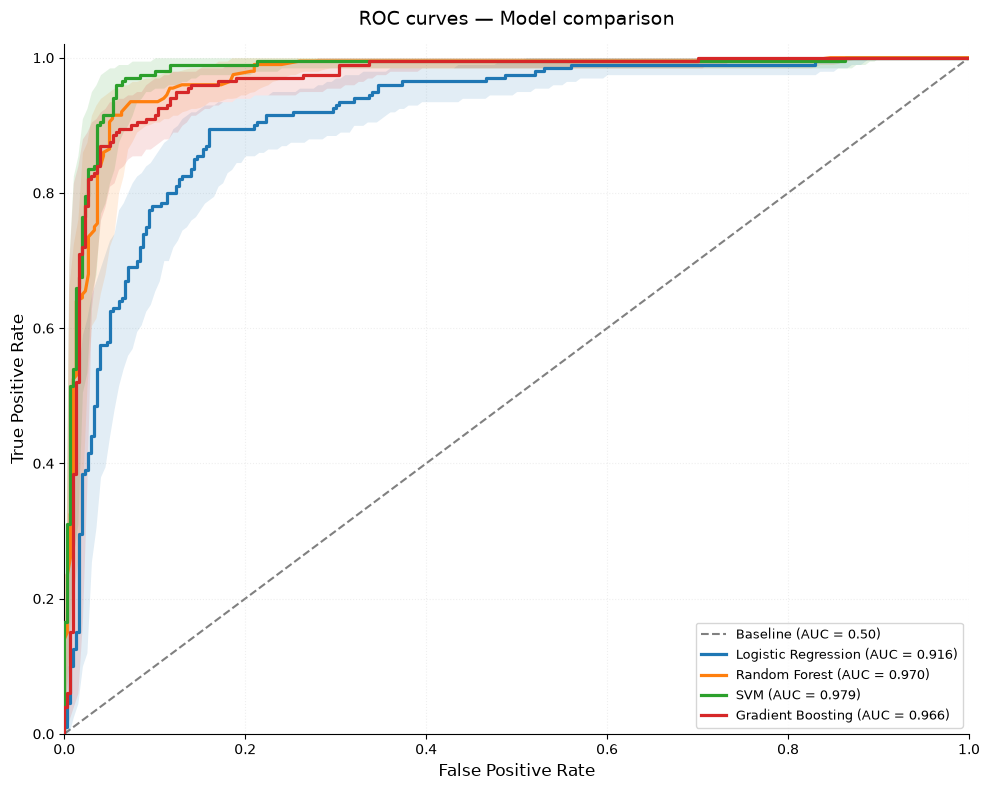

              Model      AUC  AUC CI 95% lower  AUC CI 95% upper
                SVM 0.978900          0.964511          0.989152
      Random Forest 0.970458          0.955082          0.982876
  Gradient Boosting 0.966150          0.951232          0.979551
Logistic Regression 0.915950          0.890127          0.940301


In [19]:
fig, ax, results = plot_models_roc(
    models=models,
    X_test=X_test,
    y_test=y_test,
    n_boot=1000,
    confidence=0.95,
    show_ci=True,
    show_bootstrap=False,
    random_state=42,
)

plt.show()

print(results.to_string(index=False))